# RSW / 05 — Burst entry on 1-minute bars: with or against the first burst minute (2021-01 – 2023-06)

Protocol: [`RSW 009`](../../discussions/MNQ_Regime_Switching/009_claude_rsw05_burst_entry_preregistration.md). The volatility model and the 2-state regime models (M1 HMM, WB2 Weibull HSMM) are refitted on 1-minute bars. Ticks per contract (1 tick = $0.50).

- **Entry**: at the close of the first 1-minute candle with P(burst) > 0.5, **with** or **against** that candle.
- **Exit**: at the time stop (mean burst duration in minutes + 5 minutes), at a stop, or flat at 15:55 Chicago.
- **Strategies**: 2 models × 2 directions × 5 stops (none, candle extreme + 2 ticks, 1.5 and 3 × 5-minute σ̂, 40 ticks) = 20.
- **Gates**:
  - **G1**: ≥ 150 trades.
  - **G2**: net > 0, Holm across 20 ≤ 0.05.
  - **G3**: net > 0 in ≥ 2 of 3 periods.
  - **G4**: beats the 95th percentile of the random-direction placebo.

In [1]:
import json, os, sys, tempfile, pickle
import datetime as dt
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SYNTHETIC = os.environ.get("RSW_SYNTHETIC") == "1"
SYNTH_NULL = os.environ.get("RSW_SYNTH_NULL") == "1"
if SYNTHETIC:
    os.environ["EQUITY_TRADING_DIR"] = os.environ.get("RSW_SYNTH_DIR") or tempfile.mkdtemp(prefix="rsw_")
    os.environ["RSW_SYNTH_DIR"] = os.environ["EQUITY_TRADING_DIR"]

REPO = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(REPO / "src"))
from equity_trading import mnq_predict as P
from equity_trading import regime_ar as R
from equity_trading import hsmm as HS
from equity_trading import burst_entry as E
from equity_trading import burst_reversion as B
from equity_trading import micro_bars as MB

CFG = P.SYNTH_CFG if SYNTHETIC else P.MRPConfig()
RC, EC = R.RSWConfig(), E.BEConfig()
HC = HS.HSMMConfig(D=EC.hsmm_D)
D = dt.date
OUT = Path("05"); OUT.mkdir(exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 60); pd.set_option("display.max_rows", 100)
print("engines", E.BE_VERSION, HS.HSMM_VERSION, R.RSW_VERSION, ("| synthetic " + ("null" if SYNTH_NULL else "planted continuation")) if SYNTHETIC else "| real data")
if SYNTHETIC and not (Path(os.environ["EQUITY_TRADING_DIR"]) / "Databento").exists():
    E.write_synthetic_1m(os.environ["EQUITY_TRADING_DIR"], CFG.warmup_start, CFG.train[1], CFG, cont=0.0 if SYNTH_NULL else 0.8)

engines 0.1.0 0.1.0 0.1.0 | real data


In [2]:
if SYNTHETIC:
    FIRST_FIT, REFITS, END = (CFG.train[0], D(2020, 7, 1)), CFG.refits_train, CFG.train[1]
    PERIODS = {"2020Q3": (D(2020, 7, 1), D(2020, 9, 30)), "2020Q4": (D(2020, 10, 1), D(2020, 12, 31))}
else:
    FIRST_FIT, REFITS, END = (CFG.train[0], D(2021, 1, 1)), CFG.refits_train, CFG.train[1]
    PERIODS = {"2021": (D(2021, 1, 1), D(2021, 12, 31)), "2022": (D(2022, 1, 1), D(2022, 12, 31)),
               "2023H1": (D(2023, 1, 1), D(2023, 6, 30))}
NEED_PERIODS = int(np.ceil(2 / 3 * len(PERIODS)))
m1 = MB.load_1m(CFG.root, CFG.warmup_start - dt.timedelta(days=3), END + dt.timedelta(days=1))
g = E.grid_1m(m1, EC)
g = g[(g["trade_date"] >= CFG.warmup_start) & (g["trade_date"] <= END)]
del m1
cov = E.coverage(g)
cov["flag"] = np.where(cov["minutes_per_day"] < 700, "LOW", "")
print("data coverage by month (minutes per CME day; a full MNQ day has up to 1,380 traded minutes):")
display(cov.round(0).T)
print("months flagged LOW:", list(cov.index[cov["flag"] == "LOW"].astype(str)) or "none")
expected = pd.period_range(pd.Period(CFG.warmup_start, "M"), pd.Period(END, "M"), freq="M")
missing = [str(p) for p in expected if p not in cov.index]
print("months with no data at all:", missing or "none")

data coverage by month (minutes per CME day; a full MNQ day has up to 1,380 traded minutes):


,2019-12,2020-01,2020-02,2020-03,2020-04,2020-05,2020-06,2020-07,2020-08,2020-09,2020-10,2020-11,2020-12,2021-01,2021-02,2021-03,2021-04,2021-05,2021-06,2021-07,2021-08,2021-09,2021-10,2021-11,2021-12,2022-01,2022-02,2022-03,2022-04,2022-05,2022-06,2022-07,2022-08,2022-09,2022-10,2022-11,2022-12,2023-01,2023-02,2023-03,2023-04,2023-05,2023-06
days,21,22,20,22,21,21,22,23,21,22,22,21,22,20,20,23,22,21,22,22,22,22,21,22,22,21,20,23,20,22,1,21,23,22,21,22,21,21,20,23,20,23,22
minutes,28172,29774,27075,27960,28667,28440,30029,31050,28665,29802,30030,28228,29819,27075,27074,31394,29580,28440,30071,30118,30359,30118,28980,29895,30360,28740,27360,31740,27600,30120,120,28620,31740,30120,28980,29895,28979,28740,27360,31740,27135,31500,30120
minutes_per_day,1342.0,1353.0,1354.0,1271.0,1365.0,1354.0,1365.0,1350.0,1365.0,1355.0,1365.0,1344.0,1355.0,1354.0,1354.0,1365.0,1345.0,1354.0,1367.0,1369.0,1380.0,1369.0,1380.0,1359.0,1380.0,1369.0,1368.0,1380.0,1380.0,1369.0,120.0,1363.0,1380.0,1369.0,1380.0,1359.0,1380.0,1369.0,1368.0,1380.0,1357.0,1370.0,1369.0
flag,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,LOW,,,,,,,,,,,,


months flagged LOW: ['2022-06']
months with no data at all: none


In [3]:
sig2 = E.vol_walk_forward(g, FIRST_FIT, REFITS, END, EC)
S = E.build_series_1m(g, sig2, EC)
S = S[S["trade_date"] >= CFG.train[0]]
td = S["trade_date"].to_numpy()
o = S["obs"].to_numpy(bool)
zq = S.loc[o, "z"].groupby(pd.to_datetime(S.loc[o, "trade_date"]).dt.to_period("Q")).var()
print(f"{len(S):,} minute rows | observed {o.sum():,} | var(z) by quarter:"); display(zq.round(3).to_frame().T)
FLAT = E.flat_index(S, EC)

1,203,612 minute rows | observed 1,199,467 | var(z) by quarter:


trade_date,2020Q1,2020Q2,2020Q3,2020Q4,2021Q1,2021Q2,2021Q3,2021Q4,2022Q1,2022Q2,2022Q3,2022Q4,2023Q1,2023Q2
z,1.018,1.007,1.007,1.007,1.014,1.016,1.026,1.009,1.014,1.01,1.029,1.067,1.011,1.011


## 1. Regime fits on 1-minute bars (walk-forward, cached one by one)

In [4]:
cache = OUT / f"fits_{E.BE_VERSION}{'_synth' if SYNTHETIC else ''}{'_null' if SYNTH_NULL else ''}.pkl"
FITS = pickle.load(open(cache, "rb")) if cache.exists() else {}
for a in REFITS:
    fm = td < a
    if ("M1", str(a)) not in FITS:
        t0 = dt.datetime.now(); FITS[("M1", str(a))] = R.fit(S, 2, False, fm, RC)
        pickle.dump(FITS, open(cache, "wb")); print("M1 before", a, dt.datetime.now() - t0)
    if ("WB2", str(a)) not in FITS:
        t0 = dt.datetime.now(); FITS[("WB2", str(a))] = HS.fit(S, fm, FITS[("M1", str(a))], "WB", False, HC)
        pickle.dump(FITS, open(cache, "wb")); print("WB2 before", a, dt.datetime.now() - t0, "| iter", FITS[("WB2", str(a))].n_iter)
edges = list(REFITS) + [END + dt.timedelta(days=1)]
PB, HOLD, info = {}, {}, []
for name in ("M1", "WB2"):
    pb, hold = np.full(len(S), np.nan), np.zeros(len(S), int)
    for a, b in zip(edges[:-1], edges[1:]):
        f = FITS[(name, str(a))]
        seg = (td >= a) & (td < b)
        burst = int(np.argmax(f.s2))
        if name == "M1":
            p = R.filter_run(S, f)[[f"p{k}" for k in range(2)]].to_numpy()
            mean_b, mean_c = 1 / (1 - f.A[burst, burst]), 1 / (1 - f.A[1 - burst, 1 - burst])
        else:
            p = HS.filter_run(S, f, 2.0)[[f"p{k}" for k in range(2)]].to_numpy()
            mean_b, mean_c = f.mean_duration(burst), f.mean_duration(1 - burst)
        pb[seg] = p[seg, burst]
        hold[seg] = int(round(mean_b)) + EC.extra_bars
        info.append({"model": name, "fit_before": str(a), "burst_sd": float(np.sqrt(f.s2[burst])), "calm_sd": float(np.sqrt(f.s2[1 - burst])),
                     "burst_phi": float(f.phi[burst]), "calm_phi": float(f.phi[1 - burst]), "burst_c": float(f.c[burst]),
                     "mean_burst_min": mean_b, "mean_calm_min": mean_c, "hold_min": int(round(mean_b)) + EC.extra_bars,
                     "share_pb_gt_0.5": float(np.mean(pb[seg] > EC.p_burst))})
    PB[name], HOLD[name] = pb, hold
display(pd.DataFrame(info).round(4))

M1 before 2021-01-01 0:00:34.663977
WB2 before 2021-01-01 0:00:36.513066 | iter 74
M1 before 2022-01-01 0:01:15.388087
WB2 before 2022-01-01 0:01:21.683323 | iter 82
M1 before 2023-01-01 0:01:27.047567
WB2 before 2023-01-01 0:01:45.502748 | iter 73


,model,fit_before,burst_sd,calm_sd,burst_phi,calm_phi,burst_c,mean_burst_min,mean_calm_min,hold_min,share_pb_gt_0.5
0,M1,2021-01-01,1.8007,0.7906,0.1097,-0.0343,-0.1030,2.6110,15.4868,8,0.0609
1,M1,2022-01-01,1.7347,0.7766,0.0871,-0.0431,-0.0913,3.2989,16.3644,8,0.0730
2,M1,2023-01-01,1.8715,0.7963,0.0920,-0.0363,-0.0934,2.8984,19.0123,8,0.0541
3,WB2,2021-01-01,1.7699,0.7798,0.1335,-0.0383,-0.1048,1.9617,10.6779,7,0.0683
4,WB2,2022-01-01,1.7059,0.7611,0.1149,-0.0487,-0.0915,2.1296,9.5581,7,0.0763
5,WB2,2023-01-01,1.8334,0.7817,0.1198,-0.0407,-0.0931,1.9603,11.5009,7,0.0584


In [5]:
EV = {n: E.burst_starts(S, PB[n], HOLD[n], EC) for n in ("M1", "WB2")}
for n, ev in EV.items():
    em = ev.groupby(pd.to_datetime(ev["trade_date"]).dt.to_period("M")).size()
    print(f"--- {n}: {len(ev):,} burst starts | up candles {int((ev.candle_sign > 0).sum()):,}, down {int((ev.candle_sign < 0).sum()):,} | hold minutes {sorted(ev['hold'].unique())}")
    print("burst starts per month:"); display(em.to_frame("starts").T)

--- M1: 33,917 burst starts | up candles 14,971, down 18,946 | hold minutes [np.int64(8)]
burst starts per month:


trade_date,2021-01,2021-02,2021-03,2021-04,2021-05,2021-06,2021-07,2021-08,2021-09,2021-10,2021-11,2021-12,2022-01,2022-02,2022-03,2022-04,2022-05,2022-07,2022-08,2022-09,2022-10,2022-11,2022-12,2023-01,2023-02,2023-03,2023-04,2023-05,2023-06
starts,1077,1096,1240,1201,1061,1196,1238,1162,1250,1161,1218,1247,1332,1119,1346,1253,1377,1113,1352,1263,1142,1147,1159,968,964,1133,929,1088,1085


--- WB2: 40,471 burst starts | up candles 17,983, down 22,488 | hold minutes [np.int64(7)]
burst starts per month:


trade_date,2021-01,2021-02,2021-03,2021-04,2021-05,2021-06,2021-07,2021-08,2021-09,2021-10,2021-11,2021-12,2022-01,2022-02,2022-03,2022-04,2022-05,2022-07,2022-08,2022-09,2022-10,2022-11,2022-12,2023-01,2023-02,2023-03,2023-04,2023-05,2023-06
starts,1224,1249,1415,1365,1204,1362,1424,1317,1403,1336,1389,1460,1615,1382,1648,1533,1739,1396,1649,1557,1423,1395,1418,1176,1186,1389,1142,1308,1367


## 2. Strategies: 2 models × 2 directions × 5 stops, random-direction placebo

In [6]:
rows, TR = [], {}
for n, ev in EV.items():
    for direction in EC.directions:
        sides = ev["candle_sign"].to_numpy() * (1 if direction == "with" else -1)
        for kind in EC.stops:
            tr = E.simulate(S, FLAT, ev, kind, sides, EC)
            TR[(n, direction, kind)] = tr
            st = B.stats_for(tr, PERIODS)
            plac = [E.simulate(S, FLAT, ev, kind, np.random.default_rng(seed).choice([-1, 1], len(ev)), EC)["net_ticks"].mean()
                    for seed in range(EC.n_placebo)]
            rows.append({"model": n, "direction": direction, "stop": kind, **st, "skipped_no_room": tr.attrs["skipped"],
                         "placebo_mean": float(np.nanmean(plac)), "placebo_p95": float(np.nanquantile(plac, 0.95))})
            print(n, direction, kind, "| trades", st["trades"], "| net", round(st["net"], 2) if st["trades"] >= 3 else None)
G = pd.DataFrame(rows).set_index(["model", "direction", "stop"])
G["p_holm"] = pd.Series(R.holm({k: v for k, v in G["p"].fillna(1.0).items()}))
G["periods_pos"] = sum((G[f"net_{p}"] > 0).astype(int) for p in PERIODS)
G["G1"] = G["trades"] >= EC.min_trades
G["G2"] = (G["net"] > 0) & (G["p_holm"] <= EC.alpha)
G["G3"] = G["periods_pos"] >= NEED_PERIODS
G["G4"] = G["net"] > G["placebo_p95"]
G["pass"] = G[["G1", "G2", "G3", "G4"]].all(axis=1)
for n in ("M1", "WB2"):
    print(f"=== {n}"); display(G.loc[n].round(3).T)

M1 with none | trades 23849 | net -3.35
M1 with extreme | trades 25000 | net -3.0
M1 with vol1.5 | trades 24669 | net -3.09
M1 with vol3 | trades 23943 | net -3.48
M1 with fixed40 | trades 25705 | net -3.08
M1 against none | trades 23849 | net -2.65
M1 against extreme | trades 30790 | net -2.77
M1 against vol1.5 | trades 25100 | net -2.46
M1 against vol3 | trades 24078 | net -2.46
M1 against fixed40 | trades 26084 | net -3.16
WB2 with none | trades 26710 | net -3.57
WB2 with extreme | trades 28126 | net -3.38
WB2 with vol1.5 | trades 27633 | net -3.53
WB2 with vol3 | trades 26803 | net -3.74
WB2 with fixed40 | trades 28980 | net -3.4
WB2 against none | trades 26710 | net -2.43
WB2 against extreme | trades 35757 | net -2.82
WB2 against vol1.5 | trades 28004 | net -2.31
WB2 against vol3 | trades 26910 | net -2.36
WB2 against fixed40 | trades 29319 | net -2.93
=== M1


direction           with                                         against                                      
stop                none   extreme    vol1.5      vol3  fixed40     none  extreme   vol1.5      vol3   fixed40
trades             23849     25000     24669     23943    25705    23849    30790    25100     24078     26084
gross             -1.347    -1.004     -1.09     -1.48   -1.079   -0.653   -0.767   -0.463    -0.458    -1.157
net               -3.347    -3.004     -3.09     -3.48   -3.079   -2.653   -2.767   -2.463    -2.458    -3.157
t                 -7.344    -7.679    -7.642    -7.816   -9.579   -5.822  -15.105   -6.236    -5.601   -10.732
p                    1.0       1.0       1.0       1.0      1.0      1.0      1.0      1.0       1.0       1.0
win_rate           0.438     0.409     0.423     0.437    0.366    0.481    0.145    0.457     0.479     0.396
mean_win           46.99    47.813    47.224    46.662   45.364   43.276   48.503   44.103    43.203    41.683
mean_loss        -42.585   -38.108   -39.951   -42.353  -31.095  -45.181  -11.451  -41.669   -44.436   -32.516
total_ticks     -79817.0  -75098.5  -76231.5  -83323.5 -79138.0 -63277.0 -85189.0 -61833.0  -59190.5  -82344.5
total_usd_1c    -39908.5 -37549.25 -38115.75 -41661.75 -39569.0 -31638.5 -42594.5 -30916.5 -29595.25 -41172.25
max_dd_ticks     84343.0   76493.0   78291.5   87166.0  80245.5  64941.0  85478.5  62542.5   60710.0   82777.5
worst             -902.0    -585.0    -377.5    -575.5    -62.0  -1260.0   -254.5   -473.0    -671.5    -155.0
q05               -103.0     -84.5     -92.8    -104.0    -42.5   -109.0    -24.5    -93.5    -107.5     -42.5
exit_stop            0.0     0.339     0.267      0.04    0.378      0.0    0.843    0.279     0.063     0.401
exit_time          0.996     0.658      0.73     0.956    0.618    0.996    0.156    0.718     0.933     0.596
exit_flat          0.004     0.003     0.003     0.004    0.004    0.004    0.001    0.003     0.004     0.003
mean_minutes       8.984     7.736     8.112     8.893    7.257    8.984    3.628    7.902     8.801     7.039
net_long          -4.125    -3.821    -3.783    -4.116   -3.575   -3.265   -2.522   -2.979    -2.958    -3.438
net_short         -2.735    -2.358    -2.543    -2.981   -2.686   -1.875   -3.077   -1.808    -1.823      -2.8
n_long             10496     11038     10883     10531    11343    13353    17232    14044     13481     14595
n_short            13353     13962     13786     13412    14362    10496    13558    11056     10597     11489
net_2021          -2.777    -2.577    -2.527    -2.625   -2.597   -3.223   -2.843   -3.468    -3.363    -3.511
net_2022          -3.704    -2.744    -3.153    -4.053    -2.92   -2.296   -2.487   -1.369    -1.472    -2.977
net_2023H1        -3.834    -4.523    -4.214    -4.135   -4.515   -2.166   -3.217   -2.585    -2.581    -2.772
skipped_no_room    10068      8917      9248      9974     8212    10068     3127     8817      9839      7833
placebo_mean      -3.215     -2.94    -2.862    -3.083   -3.151   -3.215    -2.94   -2.862    -3.083    -3.151
placebo_p95       -2.466    -2.672    -2.212    -2.344   -2.782   -2.466   -2.672   -2.212    -2.344    -2.782
p_holm               1.0       1.0       1.0       1.0      1.0      1.0      1.0      1.0       1.0       1.0
periods_pos            0         0         0         0        0        0        0        0         0         0
G1                  True      True      True      True     True     True     True     True      True      True
G2                 False     False     False     False    False    False    False    False     False     False
G3                 False     False     False     False    False    False    False    False     False     False
G4                 False     False     False     False    False    False    False    False     False     False
pass               False     False     False     False    False    False    False    False     False     False

=== WB2


direction           with                                         against                                      
stop                none   extreme    vol1.5      vol3  fixed40     none   extreme   vol1.5     vol3   fixed40
trades             26710     28126     27633     26803    28980    26710     35757    28004    26910     29319
gross             -1.571    -1.381    -1.533    -1.737   -1.404   -0.429    -0.823   -0.308    -0.36    -0.925
net               -3.571    -3.381    -3.533    -3.737   -3.404   -2.429    -2.823   -2.308    -2.36    -2.925
t                 -8.352    -9.545     -9.52    -9.069   -11.67    -5.68   -16.397   -6.217   -5.731   -10.453
p                    1.0       1.0       1.0       1.0      1.0      1.0       1.0      1.0      1.0       1.0
win_rate           0.432     0.405      0.42     0.431    0.367    0.483      0.15    0.464    0.481     0.403
mean_win          44.626    45.176     44.51      44.4   43.235   40.802    46.002    41.39   40.616    39.844
mean_loss        -40.275   -36.364   -38.364   -40.204  -30.414  -42.811   -11.441  -40.082  -42.256   -31.769
total_ticks     -95390.0  -95090.5  -97618.5 -100157.0 -98654.0 -64870.0 -100926.5 -64630.0 -63514.0  -85762.5
total_usd_1c    -47695.0 -47545.25 -48809.25  -50078.5 -49327.0 -32435.0 -50463.25 -32315.0 -31757.0 -42881.25
max_dd_ticks     98600.0   96339.5   98896.5  103246.0  99738.5  66150.0  101186.0  65488.0  64727.5   86586.5
worst             -930.0    -494.5    -377.5    -575.5    -62.0  -1382.0    -254.5   -428.5   -671.5    -155.0
q05                -98.0     -80.5     -90.5     -99.0    -42.5  -102.55     -24.5  -90.425   -102.0     -42.5
exit_stop            0.0     0.324     0.238     0.031    0.363      0.0     0.837    0.251    0.053     0.382
exit_time          0.997     0.673     0.759     0.965    0.634    0.997     0.162    0.746    0.943     0.615
exit_flat          0.003     0.003     0.003     0.003    0.003    0.003     0.001    0.003    0.003     0.003
mean_minutes        7.99     6.983     7.356     7.933    6.583     7.99     3.452    7.186    7.864     6.418
net_long          -4.396    -4.152    -4.259    -4.492    -3.91   -3.082    -2.589   -2.796   -2.832    -3.141
net_short         -2.918    -2.769    -2.954    -3.139   -3.002   -1.604    -3.117   -1.694   -1.764    -2.653
n_long             11799     12443     12248     11843    12838    14911     19911    15596    15024     16348
n_short            14911     15683     15385     14960    16142    11799     15846    12408    11886     12971
net_2021          -2.919    -2.801    -2.898    -2.883   -2.524   -3.081    -2.913   -3.052   -3.191    -3.287
net_2022          -3.946    -3.388    -3.849    -4.243   -3.674   -2.054    -2.499   -1.702   -1.619    -2.677
net_2023H1        -4.163    -4.608    -4.213    -4.475   -4.672   -1.837    -3.345   -2.013   -2.172     -2.71
skipped_no_room    13761     12345     12838     13668    11491    13761      4714    12467    13561     11152
placebo_mean      -2.987     -3.08    -2.812    -2.999   -3.137   -2.987     -3.08   -2.812   -2.999    -3.137
placebo_p95       -2.587    -2.881    -2.415    -2.563    -2.83   -2.587    -2.881   -2.415   -2.563     -2.83
p_holm               1.0       1.0       1.0       1.0      1.0      1.0       1.0      1.0      1.0       1.0
periods_pos            0         0         0         0        0        0         0        0        0         0
G1                  True      True      True      True     True     True      True     True     True      True
G2                 False     False     False     False    False    False     False    False    False     False
G3                 False     False     False     False    False    False     False    False    False     False
G4                 False     False     False     False    False     True      True     True     True     False
pass               False     False     False     False    False    False     False    False    False     False

## 3. Drawdowns: when the money is lost (descriptive)

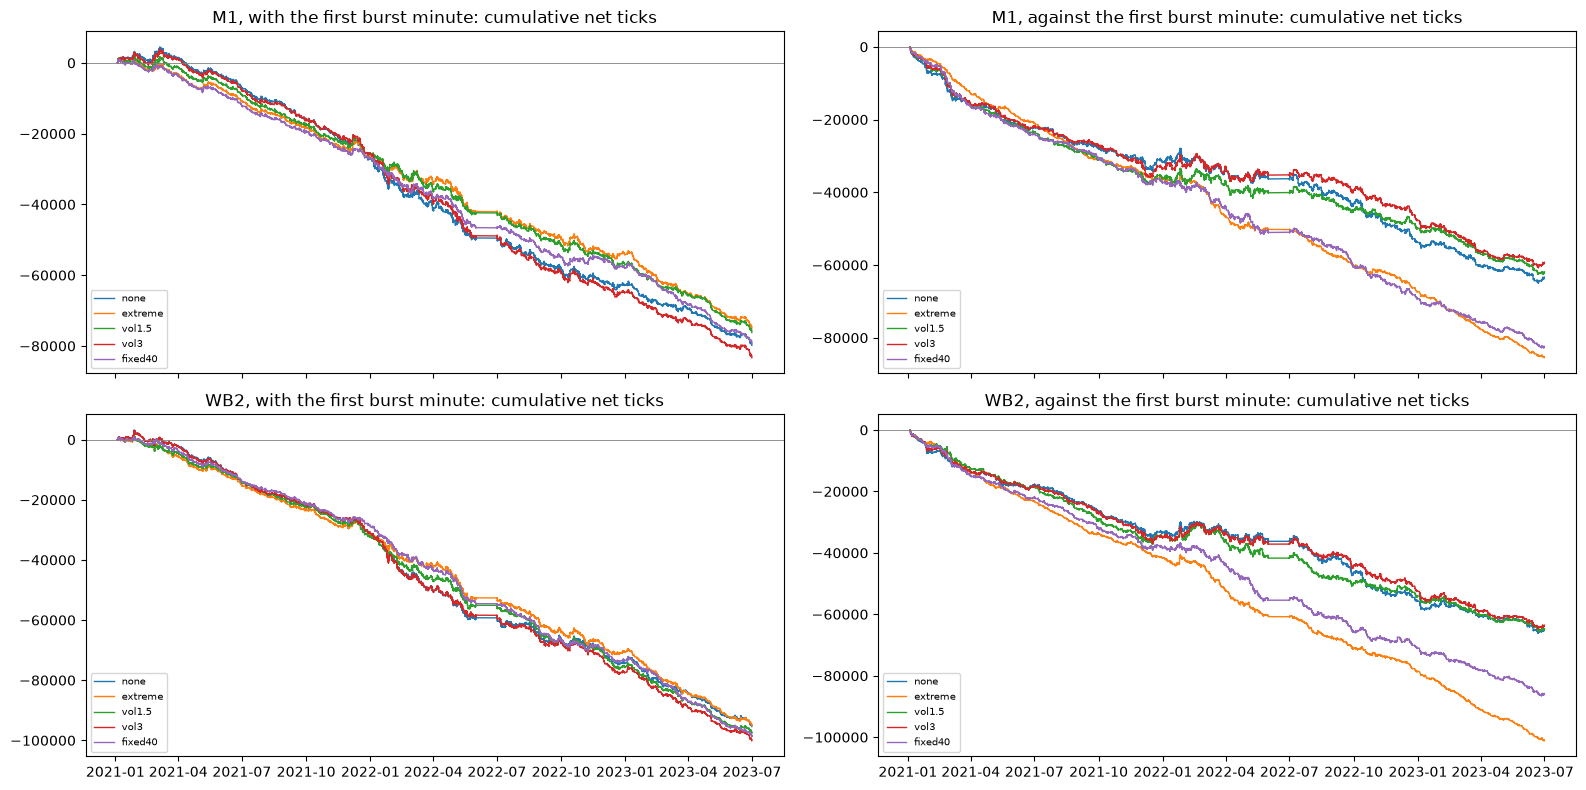

net ticks per month, 1 contract:


,M1/with/none,M1/with/extreme,M1/with/vol1.5,M1/with/vol3,M1/with/fixed40,M1/against/none,M1/against/extreme,M1/against/vol1.5,M1/against/vol3,M1/against/fixed40,WB2/with/none,WB2/with/extreme,WB2/with/vol1.5,WB2/with/vol3,WB2/with/fixed40,WB2/against/none,WB2/against/extreme,WB2/against/vol1.5,WB2/against/vol3,WB2/against/fixed40
trade_date,,,,,,,,,,,,,,,,,,,,
2021-01,2347.0,302.0,902.0,2142.0,-308.0,-6799.0,-3378.0,-5424.0,-5408.0,-4342.0,2057.0,-74.0,-206.0,1958.0,-6.0,-6947.0,-4041.0,-5176.0,-6098.0,-5392.0
2021-02,787.0,-942.0,-134.0,229.0,-482.0,-5431.0,-3801.0,-5168.0,-5464.0,-5684.0,-2016.0,-1576.0,-1840.0,-1968.0,-138.0,-3012.0,-3498.0,-2384.0,-3194.0,-3881.0
2021-03,-1683.0,-2606.0,-2044.0,-1335.0,-2842.0,-3819.0,-5702.0,-5536.0,-4914.0,-6337.0,-2202.0,-3972.0,-2539.0,-2308.0,-3545.0,-3870.0,-6394.0,-5018.0,-4302.0,-5514.0
2021-04,-4288.0,-4078.0,-3798.0,-4403.0,-3833.0,-722.0,-3324.0,-2050.0,-774.0,-2452.0,-4759.0,-4526.0,-4569.0,-4960.0,-4545.0,-803.0,-4078.0,-2054.0,-1171.0,-2312.0
2021-05,-543.0,165.0,-597.0,-416.0,-1058.0,-4089.0,-2100.0,-3164.0,-3592.0,-2994.0,-1627.0,-560.0,-964.0,-1507.0,-1254.0,-3461.0,-2716.0,-2865.0,-2844.0,-3355.0
2021-06,-3722.0,-3663.0,-3371.0,-4005.0,-3551.0,-1174.0,-2614.0,-2008.0,-1610.0,-1992.0,-5847.0,-4573.0,-4314.0,-5232.0,-4542.0,387.0,-2444.0,-804.0,-474.0,-1246.0
2021-07,-3095.0,-2779.0,-3250.0,-3236.0,-2854.0,-1855.0,-4016.0,-3241.0,-2082.0,-2314.0,-3286.0,-2978.0,-2902.0,-3291.0,-2530.0,-2162.0,-3911.0,-3682.0,-2411.0,-2998.0
2021-08,-1956.0,-2141.0,-2439.0,-1384.0,-2141.0,-2694.0,-3314.0,-2162.0,-2170.0,-2316.0,-1545.0,-2390.0,-2430.0,-1710.0,-1757.0,-3609.0,-3729.0,-3628.0,-3392.0,-4296.0
2021-09,-3961.0,-2761.0,-3002.0,-3877.0,-2614.0,-1109.0,-2215.0,-1982.0,-1064.0,-2346.0,-2549.0,-2926.0,-2794.0,-2780.0,-3307.0,-2941.0,-2750.0,-3508.0,-2928.0,-3094.0


In [7]:
fig, ax = plt.subplots(2, 2, figsize=(16, 8), sharex=True)
for i, n in enumerate(("M1", "WB2")):
    for k, direction in enumerate(EC.directions):
        a_ = ax[i, k]
        for kind in EC.stops:
            tr = TR[(n, direction, kind)]
            if len(tr):
                a_.plot(pd.to_datetime(tr["entry_ts"]), tr["net_ticks"].cumsum(), lw=1, label=kind)
        a_.axhline(0, color="grey", lw=0.6); a_.set_title(f"{n}, {direction} the first burst minute: cumulative net ticks"); a_.legend(fontsize=7)
plt.tight_layout(); plt.savefig(OUT / "equity.png", dpi=110); plt.show()
monthly = pd.DataFrame({f"{n}/{d}/{k}": TR[(n, d, k)].groupby(pd.to_datetime(TR[(n, d, k)]["trade_date"]).dt.to_period("M"))["net_ticks"].sum()
                        for n in ("M1", "WB2") for d in EC.directions for k in EC.stops if len(TR[(n, d, k)])})
print("net ticks per month, 1 contract:"); display(monthly.round(0))

## 4. Verdict

In [8]:
passed = ["/".join(k) for k in G.index[G["pass"]]]
verdict = ("CANDIDATE (2026 pre-registration): " + ", ".join(passed)) if passed else "NO_EDGE"
print(verdict)
summary = {"study": "RSW 05", "engine": E.BE_VERSION, "synthetic": SYNTHETIC, "synthetic_null": SYNTH_NULL,
           "coverage": json.loads(cov.reset_index().astype({"index": str} if "index" in cov.reset_index() else {}).to_json(orient="records", default_handler=str)),
           "fits": info, "starts": {k: int(len(v)) for k, v in EV.items()},
           "results": json.loads(G.reset_index().to_json(orient="records")), "verdict": verdict}
json.dump(summary, open(OUT / "summary.json", "w"), indent=1, default=str)
print("written", OUT / "summary.json")

NO_EDGE
written 05\summary.json
